### kSZ SBI

In [1]:
# Make the local package importable without touching original code.
from pathlib import Path
import sys
import torch

for project_root in (Path.cwd(), Path.cwd().parent):
    package_src = project_root / "src"
    if (package_src / "ksz_sbi" / "pipeline.py").is_file():
        sys.path.insert(0, str(package_src))
        break
else:
    raise FileNotFoundError("Open this notebook from the project root or notebooks/ folder")

from ksz_sbi.pipeline import Pipeline
from ksz_sbi.settings import Settings

In [3]:
pipe = Pipeline(
    # Physics / input
    input="cl",                       # "cl", "map", "a_lm"
    spectra=("gg", "vg", "vv"),       # Any subset of "gg", "vg", "vv" (for cl)
    nside=16,                    
    lmax=32,                      
    ell_min=2,                        
    cap="no_noise",                   # "sgc", "ngc", "no_noise"

    # Dataset
    data_mode="existing",             # "existing" (load), "generate" (simulate)
    n_train_parameters=30000,         # Number of training parameter pairs
    realisations_per_parameter=1,     # Number of skies per training pair
    n_heldout_parameters=2000,        # Independent held-out pairs (1 sky each)
    remove_flagged_realisations=True, # True (10xIQR filter), False (keep all)

    # SBI
    model="maf",                      # "maf", "nsf"
    embedding="fc",                   # "fc", "none", "auto"
    embedding_output_dim=8,           # output features
    embedding_hidden_dim=20,          # neurons per hidden layer
    embedding_layers=2,               # number of layers
    z_score_x="independent",          # "independent", "structured", "none"
    posterior_samples=6000,           # samples per held-out sky

    # File location  (Directory containing simulation data)
    data_root="/data/xl691/kSZCeell_sbi",  

    overwrite=False,
)


In [3]:
# Switching representation does not modify the first experiment.
'''
map_pipe = pipe.with_changes(input="map", run_name="map_maf_baseline")
alm_pipe = pipe.with_changes(input="a_lm", run_name="alm_maf_baseline")
'''

'\nmap_pipe = pipe.with_changes(input="map", run_name="map_maf_baseline")\nalm_pipe = pipe.with_changes(input="a_lm", run_name="alm_maf_baseline")\n'

In [5]:
pipe.prepare_data()

10xIQR flagged training realisations: 875


In [6]:
pipe.train()

/data/xl691/conda_envs/sbi_env/lib/python3.11/site-packages/sbi/inference/trainers/npe/npe_base.py:211: UserWarning: Data has extreme outliers in dimension(s) [310, 527, 651, 652, 713, 899, 900, 930, 1302, 1303, 1333, 1334, 1581, 1674, 1705, 1798, 1922, 2046, 2294, 2604, 3410, 3534, 3720, 3721, 3813, 4028, 4162, 4187, 4245, 4371, 4400, 4435, 4681, 4682, 4898, 4929, 4931, 5177, 5178, 5180, 5239, 5268, 5428, 5430, 5464, 5549, 5706, 5737, 5766, 5767, 5797, 5799, 5828, 5829, 5831, 5862, 5864, 5921, 5922, 5923, 5924, 5925, 5927, 5928, 5929] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 82 epochs.Saved trained posterior: /data/xl691/kSZCeell_sbi/posterior.pt


DirectPosterior sampler for potential_fn=<PosteriorBasedPotential>

In [7]:
samples = pipe.infer()

Held-out: 50/2000 inferred
Held-out: 100/2000 inferred
Held-out: 150/2000 inferred
Held-out: 200/2000 inferred
Held-out: 250/2000 inferred
Held-out: 300/2000 inferred
Held-out: 350/2000 inferred
Held-out: 400/2000 inferred
Held-out: 450/2000 inferred
Held-out: 500/2000 inferred
Held-out: 550/2000 inferred
Held-out: 600/2000 inferred
Held-out: 650/2000 inferred
Held-out: 700/2000 inferred
Held-out: 750/2000 inferred
Held-out: 800/2000 inferred
Held-out: 850/2000 inferred
Held-out: 900/2000 inferred
Held-out: 950/2000 inferred
Held-out: 1000/2000 inferred
Held-out: 1050/2000 inferred
Held-out: 1100/2000 inferred
Held-out: 1150/2000 inferred
Held-out: 1200/2000 inferred
Held-out: 1250/2000 inferred
Held-out: 1300/2000 inferred
Held-out: 1350/2000 inferred


                    accepted. It may take a long time to collect the remaining
                    5955 samples. You can prevent very long runtimes by
                    setting `max_sampling_time` to limit runtime, or disabling
                    rejection sampling (e.g. via `reject_outside_prior=False` in
                    `posterior.sample()` when available).Alternatively, consider interrupting (Ctrl-C)
                    and switching to `build_posterior(..., sample_with='mcmc')`.


Held-out: 1400/2000 inferred
Held-out: 1450/2000 inferred
Held-out: 1500/2000 inferred
Held-out: 1550/2000 inferred
Held-out: 1600/2000 inferred
Held-out: 1650/2000 inferred
Held-out: 1700/2000 inferred
Held-out: 1750/2000 inferred
Held-out: 1800/2000 inferred
Held-out: 1850/2000 inferred
Held-out: 1900/2000 inferred
Held-out: 1950/2000 inferred
Held-out: 2000/2000 inferred
Saved: /data/xl691/kSZCeell_sbi/heldout_2000_sbi_cl_fc_maf_results.npz


In [ ]:
from ksz_sbi.stability import training_seed_test, heldout_rotation_test

#training_seed_test(pipe, seeds=[1, 2, 3, 4, 5])
heldout_rotation_test(pipe, n_folds=3)

/data/xl691/conda_envs/sbi_env/lib/python3.11/site-packages/sbi/inference/trainers/npe/npe_base.py:211: UserWarning: Data has extreme outliers in dimension(s) [310, 527, 652, 713, 868, 899, 900, 931, 1085, 1178, 1209, 1303, 1333, 1334, 1582, 1612, 1674, 1705, 1707, 1798, 1860, 1922, 1924, 1953, 2046, 2294, 3317, 3410, 3534, 3720, 3721, 3813, 4028, 4162, 4187, 4245, 4371, 4397, 4403, 4435, 4652, 4681, 4682, 4898, 4929, 4931, 5177, 5178, 5180, 5239, 5265, 5430, 5464, 5488, 5520, 5549, 5706, 5737, 5766, 5767, 5797, 5799, 5828, 5829, 5831, 5864, 5921, 5922, 5923, 5924, 5925, 5927, 5928, 5929] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 70 epochs.Saved trained posterior: /data/xl691/kSZCeell_sbi/stability/heldout_rotation/posterior.pt
Fold 1: 50/2000 inferred
Fold 1: 100/2000 inferred
Fold 1: 150/2000 inferred
Fold 1: 200/2000 inferred
Fold 1: 250/2000 inferred
Fold 1: 300/2000 inferred
Fold 1: 350/2000 inferred


                    accepted. It may take a long time to collect the remaining
                    6000 samples. You can prevent very long runtimes by
                    setting `max_sampling_time` to limit runtime, or disabling
                    rejection sampling (e.g. via `reject_outside_prior=False` in
                    `posterior.sample()` when available).Alternatively, consider interrupting (Ctrl-C)
                    and switching to `build_posterior(..., sample_with='mcmc')`.


$f_{\rm NL}$: Bias = -0.08631, RMSE = 4.51960
$b_v$: Bias = -0.00021, RMSE = 0.00385


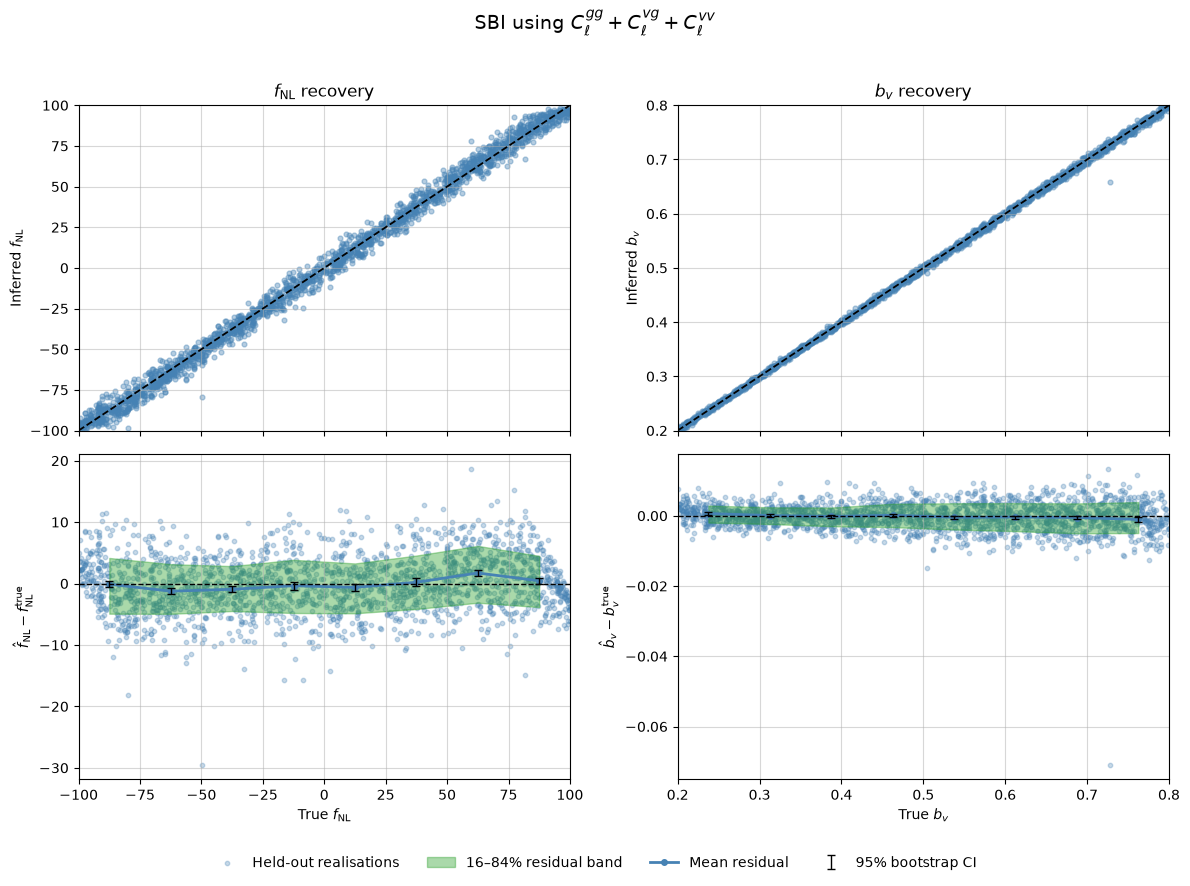

Skipping calibration: saved numerical results not found.
Training-seed stability, $f_{\rm NL}$: mean RMSE = 4.6295; SD across runs = 0.2165
Training-seed stability, $b_v$: mean RMSE = 0.0046; SD across runs = 0.0005


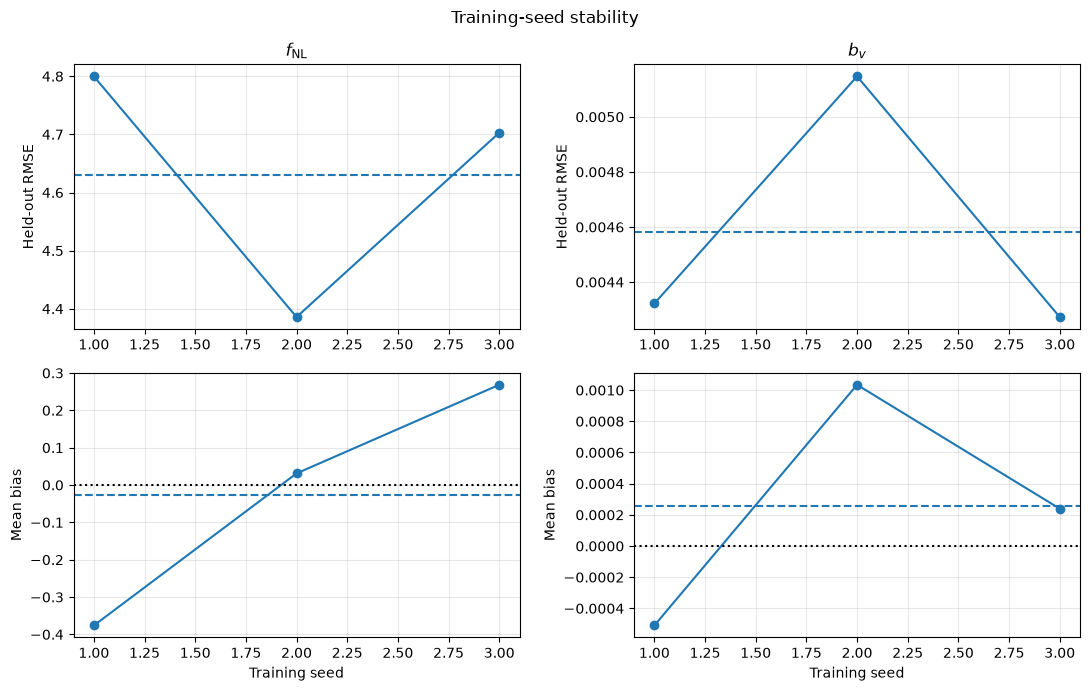

Skipping stability: saved numerical results not found.
dict_keys(['vv', 'vg', 'vg_scaledepbias', 'gg', 'gg_scaledepbias', 'gscaledepbias_gscaledepbias'])


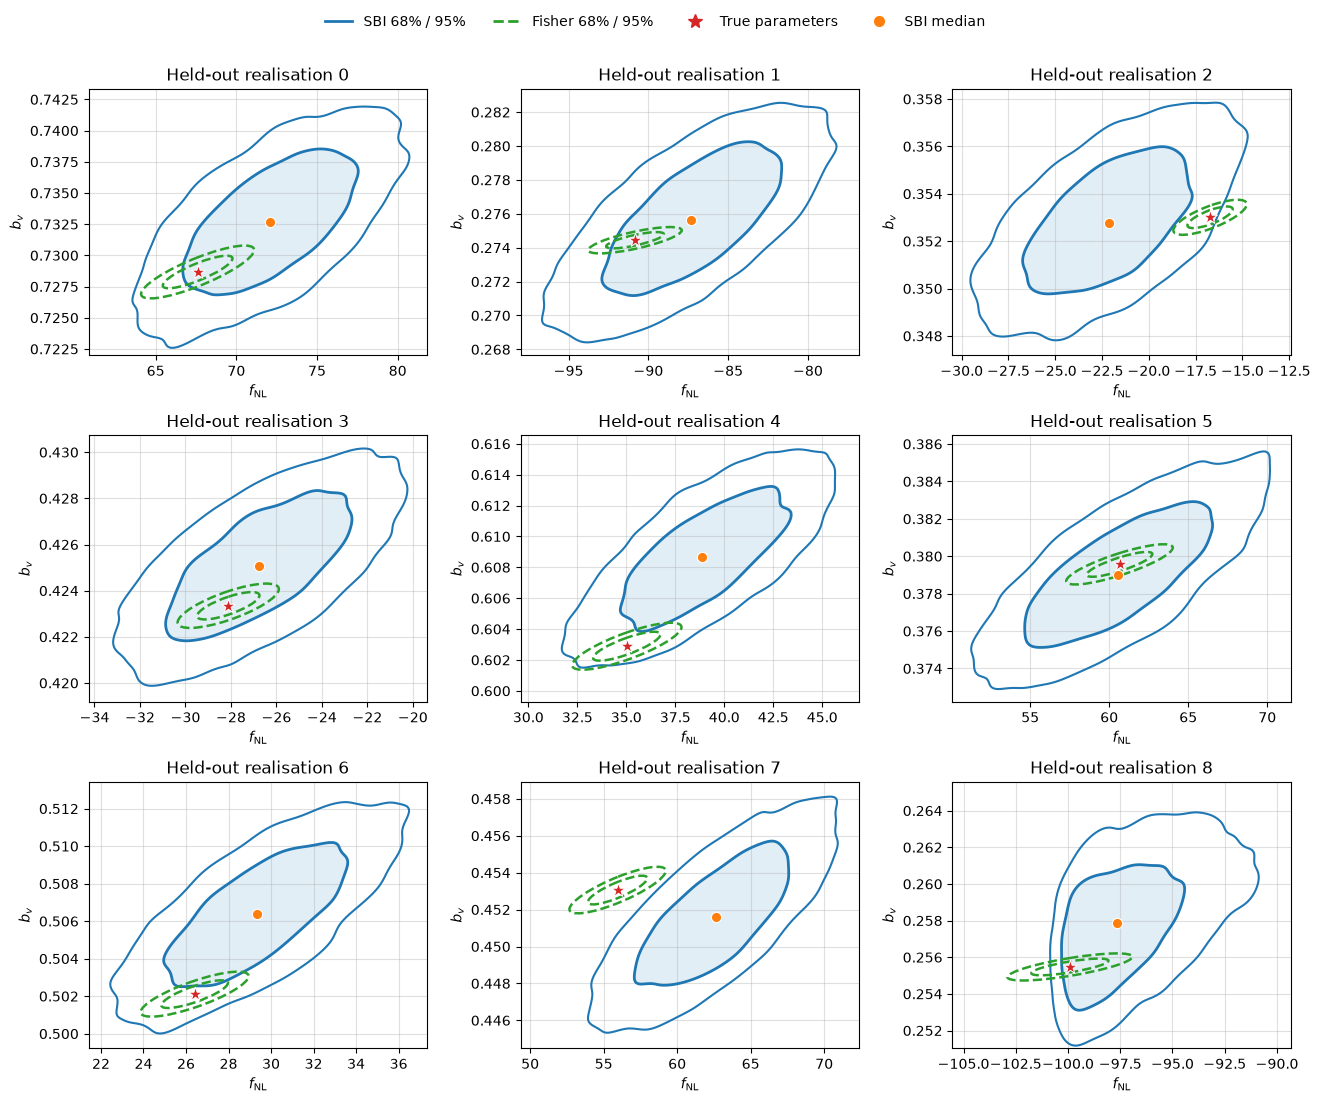

Skipping knox: saved numerical results not found.


{'recovery': <Figure size 1200x900 with 4 Axes>,
 'fisher': <Figure size 1320x1110 with 9 Axes>}

In [ ]:
pipe.result()


dict_keys(['vv', 'vg', 'vg_scaledepbias', 'gg', 'gg_scaledepbias', 'gscaledepbias_gscaledepbias'])


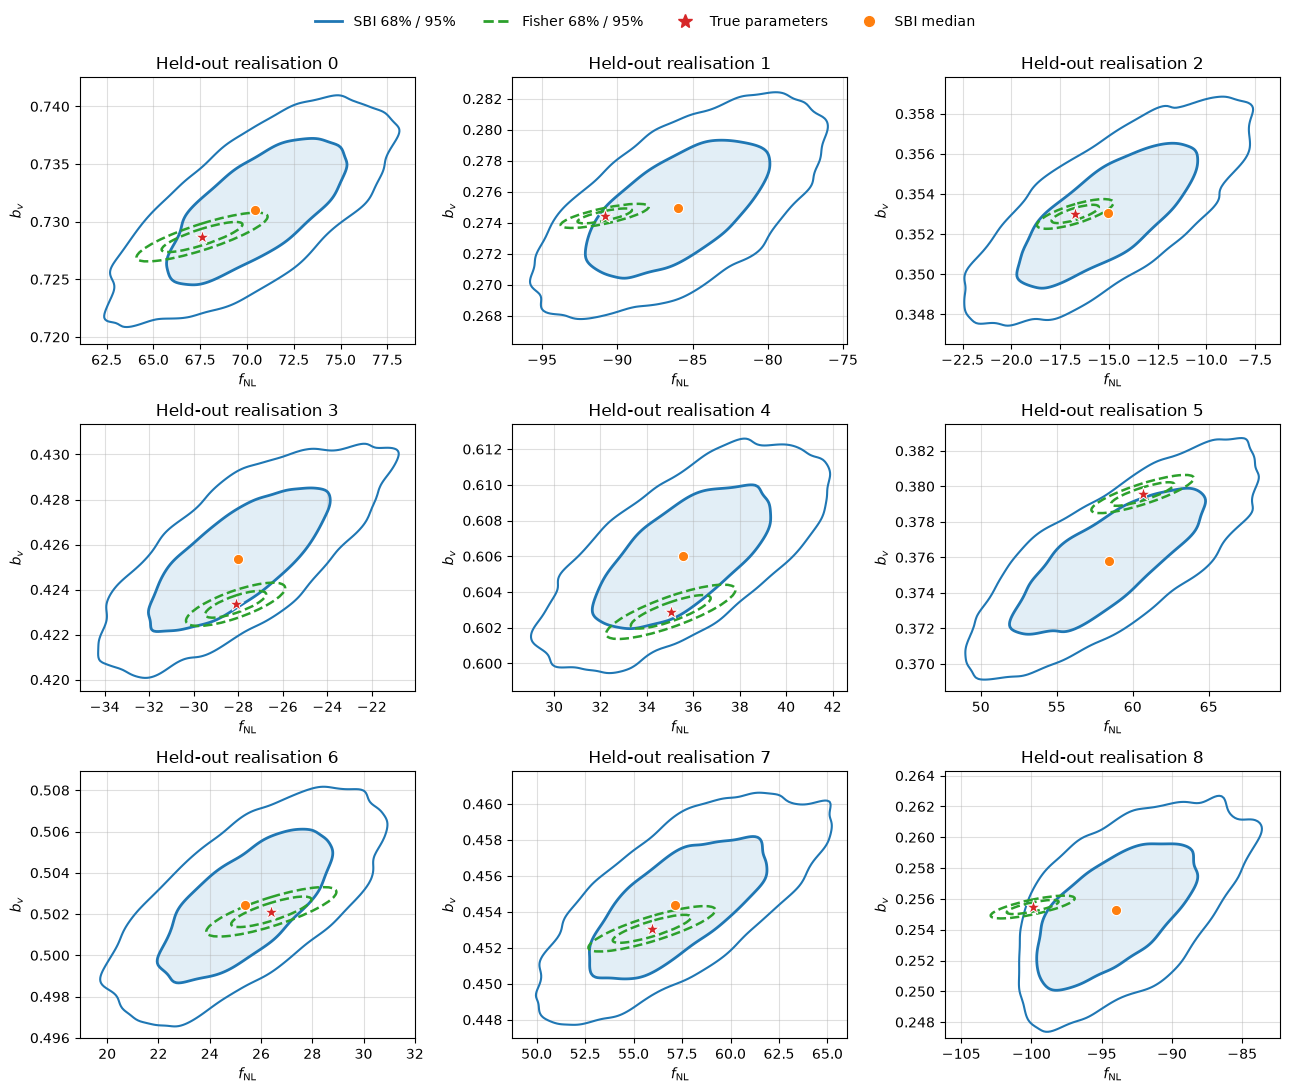

In [8]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde, chi2
from pathlib import Path
from ksz_sbi.theory import load_theory, make_theory_cls

# ============================================================
# 1. Load results
# ============================================================
cfg = pipe.settings
root = Path(cfg.data_root)

samples_all = np.load(root / "posterior_samples.npz")["samples"]
theta_all = np.load(root / "heldout_data.npz")["theta_test"]
cls = load_theory(cfg)

color="tab:blue"     # SBI
color="tab:green"    # Fisher
color="tab:red"      # Truth
color="tab:orange"   # Median


# ============================================================
# 2. Theoretical covariance
# ============================================================
def cov(theta):
    gg, vg, vv = make_theory_cls(*theta, cls, cap=cfg.cap)

    top = np.concatenate([gg, vg.transpose(1, 0, 2)], axis=1)
    bottom = np.concatenate([vg, vv], axis=1)

    return np.concatenate([top, bottom], axis=0)


# ============================================================
# 3. Fisher covariance
# ============================================================
def fisher_cov(theta):
    C = cov(theta)

    dC = [
        (cov(theta + h*np.eye(2)[i]) -
         cov(theta - h*np.eye(2)[i])) / (2*h)
        for i, h in enumerate([1.0, 0.001])
    ]

    F = np.zeros((2, 2))

    for ell in range(max(2, cfg.ell_min), cfg.lmax + 1):
        A = [
            np.linalg.solve(C[:, :, ell], d[:, :, ell])
            for d in dC
        ]

        F += (2*ell + 1)/2 * np.array([
            [np.trace(a @ b) for b in A] for a in A
        ])

    return np.linalg.inv(F)

# ============================================================
# 4. Plot SBI + Fisher (3x3)
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(13, 11))

for j, ax in enumerate(axes.flat):

    samples = samples_all[j]
    true = theta_all[j]
    median = np.median(samples, axis=0)
    Sigma = fisher_cov(true)

    # Local zoom
    std = np.sqrt(np.diag(Sigma))

    lo = np.minimum(
        np.percentile(samples, 1, axis=0),
        true - 3.5 * std
    )
    hi = np.maximum(
        np.percentile(samples, 99, axis=0),
        true + 3.5 * std
    )

    pad = 0.1 * (hi - lo)
    lo, hi = lo - pad, hi + pad

    X, Y = np.meshgrid(
        np.linspace(lo[0], hi[0], 150),
        np.linspace(lo[1], hi[1], 150)
    )

    # SBI posterior contours
    Z = gaussian_kde(samples.T)(
        np.vstack([X.ravel(), Y.ravel()])
    ).reshape(X.shape)

    z = np.sort(Z.ravel())[::-1]
    cum = np.cumsum(z) / z.sum()

    l95, l68 = [
        z[np.searchsorted(cum, p)]
        for p in (0.95, 0.68)
    ]

    ax.contourf(
        X, Y, Z,
        levels=[l68, Z.max()],
        colors=["#dbeaf4"],
        alpha=0.8
    )

    ax.contour(
        X, Y, Z,
        levels=[l95, l68],
        colors=["tab:blue", "tab:blue"],
        linewidths=[1.5, 2.0]
    )

    # Fisher 68% and 95% ellipses
    vals, vecs = np.linalg.eigh(Sigma)
    order = np.argsort(vals)[::-1]
    vals = vals[order]
    vecs = vecs[:, order]

    angle = np.degrees(
        np.arctan2(vecs[1, 0], vecs[0, 0])
    )

    for p in (0.68, 0.95):
        r = np.sqrt(chi2.ppf(p, df=2))

        ax.add_patch(Ellipse(
            xy=true,
            width=2 * r * np.sqrt(vals[0]),
            height=2 * r * np.sqrt(vals[1]),
            angle=angle,
            fill=False,
            edgecolor="tab:green",
            linestyle="--",
            linewidth=1.8,
            zorder=4
        ))

    # True and inferred parameters
    ax.scatter(
        *true,
        color="tab:red",
        marker="*",
        s=110,
        edgecolors="white",
        linewidths=0.7,
        zorder=5
    )

    ax.scatter(
        *median,
        color="tab:orange",
        marker="o",
        s=55,
        edgecolors="white",
        linewidths=0.8,
        zorder=6
    )

    ax.set(
        xlim=(lo[0], hi[0]),
        ylim=(lo[1], hi[1]),
        xlabel=r"$f_{\rm NL}$",
        ylabel=r"$b_v$",
        title=f"Held-out realisation {j}"
    )

    ax.grid(alpha=0.4)


# ============================================================
# 5. Shared legend
# ============================================================
legend = [
    Line2D(
        [0], [0],
        color="tab:blue",
        lw=2,
        label="SBI 68% / 95%"
    ),
    Line2D(
        [0], [0],
        color="tab:green",
        lw=2,
        ls="--",
        label="Fisher 68% / 95%"
    ),
    Line2D(
        [0], [0],
        marker="*",
        linestyle="None",
        markerfacecolor="tab:red",
        markeredgecolor="tab:red",
        markersize=10,
        label="True parameters"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor="tab:orange",
        markeredgecolor="tab:orange",
        markersize=7,
        label="SBI median"
    )
]

fig.legend(
    handles=legend,
    loc="upper center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.995)
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

$f_{\rm NL}$: Bias = 0.06923, RMSE = 4.45359
$b_v$: Bias = 0.00002, RMSE = 0.00549


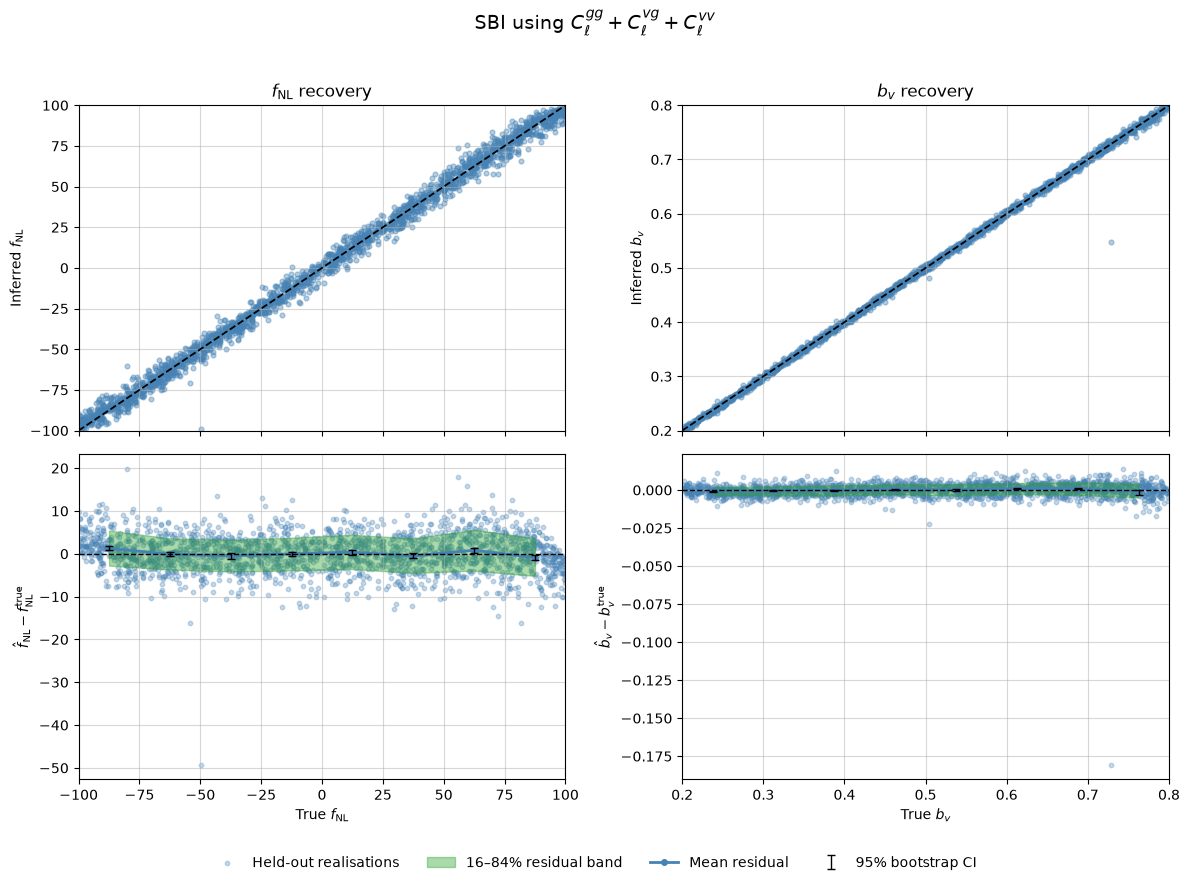

In [9]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root = Path(pipe.settings.data_root)
samples = np.load(root / "posterior_samples.npz")["samples"]
true = np.load(root / "heldout_data.npz")["theta_test"]

inferred = np.median(samples, axis=1)
residual = inferred - true

rng = np.random.default_rng(12345)
NBINS, NBOOT = 8, 1000

names = [r"$f_{\rm NL}$", r"$b_v$"]
res_names = [
    r"$\hat f_{\rm NL}-f_{\rm NL}^{\rm true}$",
    r"$\hat b_v-b_v^{\rm true}$"
]
bounds = [pipe.settings.fNL_prior, pipe.settings.bv_prior]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex="col")

for k in range(2):
    x, y = true[:, k], inferred[:, k]
    r = y - x

    # 1. Inferred vs true
    ax = axes[0, k]
    ax.scatter(x, y, s=12, color="steelblue", alpha=0.4)
    ax.plot(bounds[k], bounds[k], "k--", lw=1.3)
    ax.set(xlim=bounds[k], ylim=bounds[k],
           ylabel="Inferred " + names[k],
           title=names[k] + " recovery")
    ax.grid(alpha=0.5)

    # 2. Binned residual statistics
    edges = np.linspace(*bounds[k], NBINS + 1)
    centers = (edges[:-1] + edges[1:]) / 2
    means, q16, q84, ci_lo, ci_hi = [], [], [], [], []

    for i in range(NBINS):
        mask = (x >= edges[i]) & (x < edges[i+1] if i < NBINS-1 else x <= edges[i+1])
        values = r[mask]

        means.append(values.mean())
        q16.append(np.percentile(values, 16))
        q84.append(np.percentile(values, 84))

        boot = rng.choice(values, (NBOOT, len(values)), replace=True).mean(axis=1)
        ci_lo.append(np.percentile(boot, 2.5))
        ci_hi.append(np.percentile(boot, 97.5))

    means = np.array(means)

    # 3. Residual plot
    ax = axes[1, k]
    ax.scatter(x, r, s=10, color="steelblue", alpha=0.3,
               label="Held-out realisations")

    ax.fill_between(centers, q16, q84, color="tab:green", alpha=0.4,
                    label="16–84% residual band")

    ax.plot(centers, means, "-o", color="steelblue", lw=2, ms=4,
            label="Mean residual")

    ax.errorbar(centers, means,
                yerr=[means-np.array(ci_lo), np.array(ci_hi)-means],
                fmt="none", color="black", capsize=3, lw=1,
                label="95% bootstrap CI")

    ax.axhline(0, color="black", ls="--", lw=1)
    ax.set(xlim=bounds[k], xlabel="True " + names[k], ylabel=res_names[k])
    ax.grid(alpha=0.5)

    print(f"{names[k]}: Bias = {r.mean():.5f}, RMSE = {np.sqrt(np.mean(r**2)):.5f}")

handles, labels = axes[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4,
           frameon=False, bbox_to_anchor=(0.5, 0.01))

fig.suptitle(r"SBI using $C_\ell^{gg}+C_\ell^{vg}+C_\ell^{vv}$", fontsize=14)
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()


Sampling 2000 times (1000,) posterior samples.:   0%|          | 0/2000 [00:00<?, ?it/s]

Sampling 2000 times (1000,) posterior samples.:  15%|█▌        | 309/2000 [00:03<00:19, 86.76it/s]WARNING:root:Only 0.409% proposal samples are
                    accepted. It may take a long time to collect the remaining
                    955 samples. You can prevent very long runtimes by
                    setting `max_sampling_time` to limit runtime, or disabling
                    rejection sampling (e.g. via `reject_outside_prior=False` in
                    `posterior.sample()` when available).Alternatively, consider interrupting (Ctrl-C)
                    and switching to `build_posterior(..., sample_with='mcmc')`.
Calculating ranks for 2000 SBC samples: 100%|██████████| 2000/2000 [00:00<00:00, 14895.71it/s]


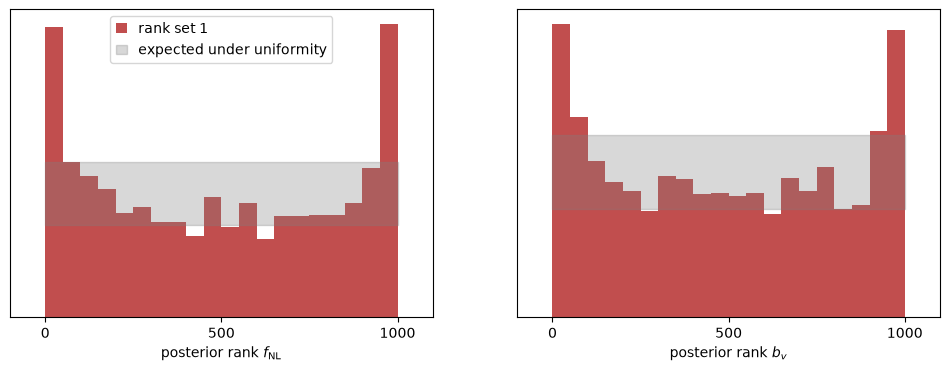

KS p-values:  tensor([5.2821e-12, 1.3781e-09])
C2ST ranks:   tensor([0.7150, 0.7042], dtype=torch.float64)
C2ST DAP:     tensor([0.5010, 0.5048], dtype=torch.float64)


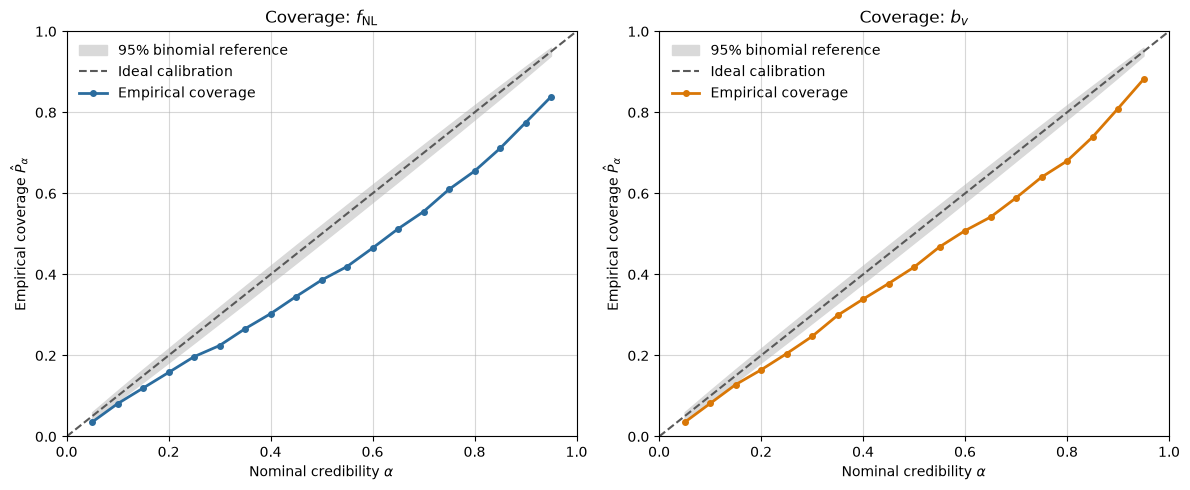

In [10]:

import numpy as np
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import binom

from sbi.diagnostics import run_sbc
from sbi.analysis.plot import sbc_rank_plot

# ============================================================
# 1. Load saved model and held-out data
# ============================================================
root = Path(pipe.settings.data_root)

data = np.load(root / "heldout_data.npz")
theta = torch.from_numpy(data["theta_test"]).float()
x = torch.from_numpy(data["x_test"]).float()

posterior = torch.load(
    root / "posterior.pt",
    map_location="cpu",
    weights_only=False
)

# ============================================================
# 2. Official SBI calibration
# ============================================================
NSAMP = 1000

ranks, dap_samples = run_sbc(
    theta,
    x,
    posterior,
    num_posterior_samples=NSAMP,
    use_batched_sampling=False
)

# ============================================================
# 3. SBC rank histograms (official SBI plot)
# ============================================================
fig, axes = sbc_rank_plot(
    ranks,
    NSAMP,
    plot_type="hist",
    num_bins=20,
    parameter_labels=[r"$f_{\rm NL}$", r"$b_v$"],
    figsize=(12, 4)
)
plt.show()

from sbi.diagnostics import check_sbc

check_stats = check_sbc(
    ranks,
    theta,
    dap_samples,
    num_posterior_samples=NSAMP
)

print("KS p-values: ", check_stats["ks_pvals"])
print("C2ST ranks:  ", check_stats["c2st_ranks"])
print("C2ST DAP:    ", check_stats["c2st_dap"])

# ============================================================
# 4. Coverage from the same SBI ranks
# ============================================================
u = ranks.detach().cpu().numpy() / NSAMP
R = len(u)
alphas = np.linspace(0.05, 0.95, 19)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
names = [r"$f_{\rm NL}$", r"$b_v$"]
colors = ["#2b6c9e", "#d97706"]

for k, ax in enumerate(axes):

    coverage = np.array([
        np.mean(
            (u[:, k] >= (1-a)/2) &
            (u[:, k] <= (1+a)/2)
        )
        for a in alphas
    ])

    # Exact pointwise 95% binomial reference band
    lower = binom.ppf(0.025, R, alphas) / R
    upper = binom.ppf(0.975, R, alphas) / R

    ax.fill_between(
        alphas, lower, upper,
        color="0.85", label="95% binomial reference"
    )

    ax.plot(
        [0, 1], [0, 1], "--",
        color="0.35", label="Ideal calibration"
    )

    ax.plot(
        alphas, coverage, "-o",
        color=colors[k], lw=2, ms=4,
        label="Empirical coverage"
    )

    ax.set(
        xlim=(0, 1),
        ylim=(0, 1),
        xlabel=r"Nominal credibility $\alpha$",
        ylabel=r"Empirical coverage $\hat P_\alpha$",
        title=f"Coverage: {names[k]}"
    )

    ax.grid(alpha=0.5)
    ax.legend(frameon=False)

plt.tight_layout()
plt.show()


dict_keys(['vv', 'vg', 'vg_scaledepbias', 'gg', 'gg_scaledepbias', 'gscaledepbias_gscaledepbias'])


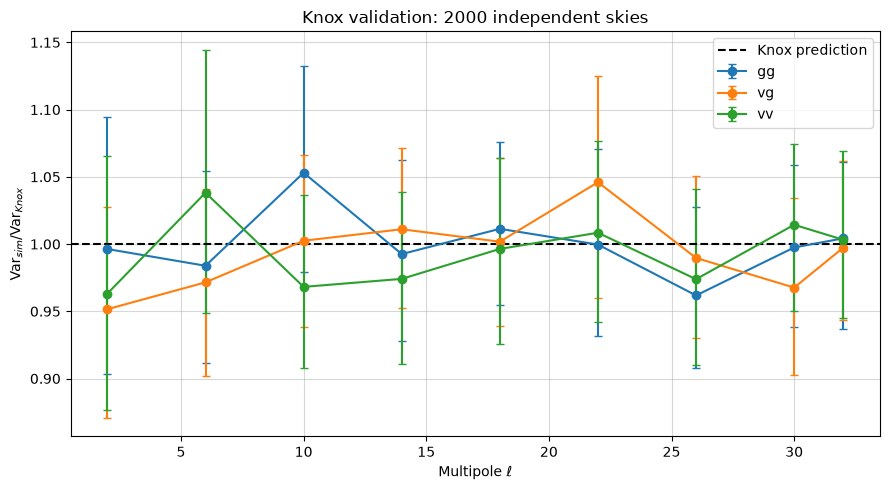

Mean R over ell=2..32:
gg: 1.002
vg: 0.996
vv: 0.999


In [11]:

import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from ksz_sbi.theory import load_theory, make_theory_cls

# --------------------------------------------------
# 1. Fixed parameters and theoretical spectra
# --------------------------------------------------
cfg = pipe.settings
Nsim = 2000
Nboot = 400
fNL, bv = 0.0, 0.5

cls = load_theory(cfg)
gg, vg, vv = make_theory_cls(fNL, bv, cls, cap=cfg.cap)

n, L = cfg.nbins, cfg.lmax
ell = np.arange(2, L + 1)

# Same covariance construction as simulator.py
S = np.zeros((2*n, 2*n, L+1))
S[:n, :n] = gg
S[n:, n:] = vv
S[n:, :n] = vg
S[:n, n:] = vg.transpose(1, 0, 2)

# Same ordering used by hp.synalm(new=True)
cls_hp = (
    [S[i, i] for i in range(2*n)]
    + [S[i, i+d] for d in range(1, 2*n)
       for i in range(2*n-d)]
)

# --------------------------------------------------
# 2. Generate independent skies (no maps)
# --------------------------------------------------
draws = np.empty((Nsim, 3, len(ell)))

for r in range(Nsim):
    np.random.seed(2000000 + r)
    alms = hp.synalm(cls_hp, lmax=L, new=True)

    draws[r, 0] = hp.alm2cl(alms[0], alms[0])[2:]   # gg
    draws[r, 1] = hp.alm2cl(alms[n], alms[0])[2:]   # vg
    draws[r, 2] = hp.alm2cl(alms[n], alms[n])[2:]   # vv

# --------------------------------------------------
# 3. Knox prediction and simulation variance
# --------------------------------------------------
Cgg = S[0, 0, 2:]
Cvg = S[n, 0, 2:]
Cvv = S[n, n, 2:]

V_knox = np.array([
    2*Cgg**2,
    Cvv*Cgg + Cvg**2,
    2*Cvv**2
]) / (2*ell + 1)

R = draws.var(axis=0, ddof=1) / V_knox

# --------------------------------------------------
# 4. Bootstrap 95% error bars
# --------------------------------------------------
rng = np.random.default_rng(123)
R_boot = np.empty((Nboot, 3, len(ell)))

for b in range(Nboot):
    idx = rng.integers(0, Nsim, Nsim)
    R_boot[b] = draws[idx].var(axis=0, ddof=1) / V_knox

lo, hi = np.percentile(R_boot, [2.5, 97.5], axis=0)

# --------------------------------------------------
# 5. Plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))

points = np.r_[np.arange(0, len(ell), 4), len(ell)-1]

for k, label in enumerate(["gg", "vg", "vv"]):
    ax.errorbar(
        ell[points], R[k, points],
        yerr=[
            R[k, points] - lo[k, points],
            hi[k, points] - R[k, points]
        ],
        fmt="o-", capsize=3, label=label
    )

ax.axhline(1, color="black", linestyle="--",
           label="Knox prediction")
ax.set(
    xlabel=r"Multipole $\ell$",
    ylabel=r"$\mathrm{Var}_{sim}/\mathrm{Var}_{Knox}$",
    title=f"Knox validation: {Nsim} independent skies"
)
ax.legend()
ax.grid(alpha=0.5)

plt.tight_layout()
plt.show()

print("Mean R over ell=2..32:")
for label, values in zip(["gg", "vg", "vv"], R):
    print(f"{label}: {values.mean():.3f}")


dict_keys(['vv', 'vg', 'vg_scaledepbias', 'gg', 'gg_scaledepbias', 'gscaledepbias_gscaledepbias'])
Spectra: 136
gg, vg, vv: [36 64 36]


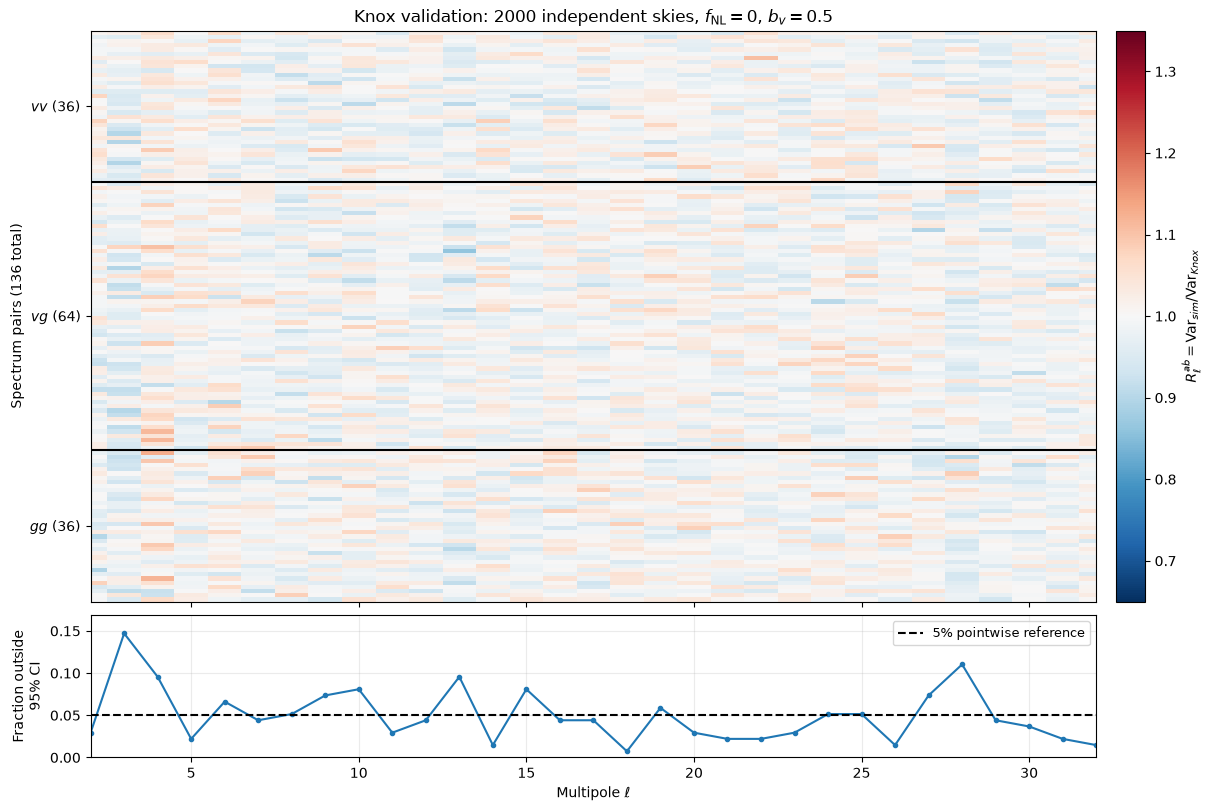


Mean variance ratio over all multipoles:
gg: mean R = 0.9979, outside 95% CI = 5.7%
vg: mean R = 0.9968, outside 95% CI = 5.0%
vv: mean R = 0.9965, outside 95% CI = 4.2%
All 136: mean R = 0.9970


In [12]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from ksz_sbi.theory import load_theory, make_theory_cls

# ============================================================
# 1. SETTINGS AND THEORETICAL COVARIANCE
# ============================================================
cfg = pipe.settings
Nsim = 2000
Nboot = 1500
fNL, bv = 0.0, 0.5

cls = load_theory(cfg)
gg, vg, vv = make_theory_cls(fNL, bv, cls, cap=cfg.cap)

n, L = cfg.nbins, cfg.lmax
ell = np.arange(2, L + 1)
nf = 2 * n

S = np.zeros((nf, nf, L + 1))
S[:n, :n] = gg
S[n:, n:] = vv
S[n:, :n] = vg
S[:n, n:] = vg.transpose(1, 0, 2)

# healpy diagonal ordering
pairs_hp = (
    [(i, i) for i in range(nf)]
    + [(i, i+d) for d in range(1, nf)
       for i in range(nf-d)]
)

cls_hp = [S[i, j] for i, j in pairs_hp]

# Group into gg, vg, vv
group_hp = np.array([
    0 if j < n else (1 if i < n else 2)
    for i, j in pairs_hp
])

order = np.argsort(group_hp, kind="stable")
pairs = np.array(pairs_hp)[order]
groups = group_hp[order]

a, b = pairs.T
Npair = len(pairs)

print("Spectra:", Npair)
print("gg, vg, vv:", np.bincount(groups))

# ============================================================
# 2. GENERATE 2000 INDEPENDENT SKIES
# ============================================================
draws = np.empty((Nsim, Npair, len(ell)))

for r in range(Nsim):
    np.random.seed(2000000 + r)
    alms = hp.synalm(cls_hp, lmax=L, new=True)

    # All 136 auto/cross spectra, ordered by diagonal
    cl_all = np.asarray(hp.alm2cl(alms))
    draws[r] = cl_all[order, 2:]

# ============================================================
# 3. KNOX VARIANCE FOR ALL 136 SPECTRA
# ============================================================
V_knox = (
    S[a, a, 2:] * S[b, b, 2:]
    + S[a, b, 2:]**2
) / (2 * ell + 1)

if np.any(V_knox <= 0):
    raise ValueError("Non-positive Knox variance detected.")

R = draws.var(axis=0, ddof=1) / V_knox

# ============================================================
# 4. BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
rng = np.random.default_rng(123)
R_boot = np.empty((Nboot, Npair, len(ell)))

for k in range(Nboot):
    idx = rng.integers(0, Nsim, Nsim)
    R_boot[k] = (
        draws[idx].var(axis=0, ddof=1) / V_knox
    )

lo, hi = np.percentile(R_boot, [2.5, 97.5], axis=0)

# Cells where the pointwise bootstrap CI excludes R=1
outside = (lo > 1) | (hi < 1)
fraction_outside = outside.mean(axis=0)

# ============================================================
# 5. COMPLETE VALIDATION FIGURE
# ============================================================
fig, (ax, ax2) = plt.subplots(
    2, 1, figsize=(12, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [4, 1]},
    layout="constrained"
)

im = ax.imshow(
    R,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    extent=[1.5, L+0.5, -0.5, Npair-0.5],
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=0.65, vcenter=1, vmax=1.35)
)

# Boundaries between gg / vg / vv
ax.axhline(35.5, color="black", lw=1.5)
ax.axhline(99.5, color="black", lw=1.5)

ax.set_yticks(
    [17.5, 67.5, 117.5],
    [r"$gg$ (36)", r"$vg$ (64)", r"$vv$ (36)"]
)
ax.set_ylabel("Spectrum pairs (136 total)")
ax.set_title(
    f"Knox validation: {Nsim} independent skies, "
    rf"$f_{{\rm NL}}={fNL:g}$, $b_v={bv:g}$"
)

cb = fig.colorbar(im, ax=ax, pad=0.02)
cb.set_label(r"$R_\ell^{ab} = "
             r"\mathrm{Var}_{sim}/\mathrm{Var}_{Knox}$")

ax2.plot(ell, fraction_outside, "o-", ms=3)
ax2.axhline(
    0.05, color="black", ls="--",
    label="5% pointwise reference"
)
ax2.set(
    xlabel=r"Multipole $\ell$",
    ylabel="Fraction outside\n95% CI",
    xlim=(2, L),
    ylim=(0, max(0.15, fraction_outside.max()*1.15))
)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.25)

plt.show()

# ============================================================
# 6. NUMERICAL SUMMARY
# ============================================================
print("\nMean variance ratio over all multipoles:")
for k, name in enumerate(["gg", "vg", "vv"]):
    mask = groups == k
    print(
        f"{name}: mean R = {R[mask].mean():.4f}, "
        f"outside 95% CI = {outside[mask].mean():.1%}"
    )

print(f"All 136: mean R = {R.mean():.4f}")
